# 02 - Normalisation, filtre injection, déduplication et split (CSIC 2010)

**Entrée :** `data/raw/csic2010/csic_database.csv` · **Sorties :** `data/processed/train.csv` et `val.csv`

**Objectif.** Transformer les 61 065 requêtes brutes de CSIC 2010 en un jeu d'entraînement propre :
1. une représentation **texte unique** pour chaque requête  ;
2. ne garder, parmi les anomalies, que celles qui sont **vraiment des injections** (SQLi / XSS) ;
3. supprimer les **doublons** ;
4. **mélanger** puis couper en **80 % train / 20 % validation**, stratifié.


## 0. Préparation

 On importe les outils et on indique à Python où se trouve le projet, pour pouvoir réutiliser
le code de `src/` (les fonctions écrites dans `normalize.py`) au lieu de le recopier dans le notebook.

In [2]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Racine du projet = dossier parent de notebooks/
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))          # permet : from src.preprocessing... import ...

from src.preprocessing.normalize import (
    normalize_request, injection_markers, looks_like_injection, url_decode_repeated,
)

pd.set_option("display.max_colwidth", 120)   

## 1. Charger les données brutes

 On lit le CSV de CSIC 2010. Rappel de l'EDA (notebook 01) : 61 065 lignes, 36 000 normales et
25 065 anormales. On ne garde que `Method`, `URL`, `content` (le corps) et `classification` (l'étiquette).
Toutes les autres colonnes sont constantes, redondantes ou propres à la source (cookie...).

In [3]:
raw = pd.read_csv(ROOT / "data" / "raw" / "csic2010" / "csic_database.csv")
raw = raw[["Method", "URL", "content", "classification"]]   # colonnes retenues par l'EDA
print(raw.shape)
raw["classification"].value_counts()

(61065, 4)


classification
0    36000
1    25065
Name: count, dtype: int64

## 2. Normalisation : un seul texte par requête
La fonction `normalize_request(method, url, body)` fait, dans l'ordre :
1. supprime `http://localhost:8080` et ` HTTP/1.1` (propres au lab CSIC) ;
2. assemble `méthode + chemin/paramètres + corps` ;
3. **décode l'URL** (`%27` devient `'`) ;
4. passe en **minuscules** et nettoie les espaces.

On regarde 3 exemples *avant → après*.

In [4]:
exemples = raw.sample(3, random_state=7)
for _, r in exemples.iterrows():
    print("AVANT :", r["Method"], r["URL"], "|", r["content"])
    print("APRES :", normalize_request(r["Method"], r["URL"], r["content"]))
    print()

AVANT : POST http://localhost:8080/tienda1/miembros/editar.jsp HTTP/1.1 | modo=registro&login=myrtie&password=9uBIleTE&nombre=Aelohim&apellidos=Coria+Echecopar&email=bonnafe%40prensahp.mn&dni=12879968Z&direccion=C%2F+Vivers+102+&ciudadA=Moralina&cp=24288&provincia=Madrid&ntc=0201643055570272&B1=Registrar
APRES : post /tienda1/miembros/editar.jsp modo=registro&login=myrtie&password=9ubilete&nombre=aelohim&apellidos=coria echecopar&email=bonnafe@prensahp.mn&dni=12879968z&direccion=c/ vivers 102 &ciudada=moralina&cp=24288&provincia=madrid&ntc=0201643055570272&b1=registrar

AVANT : GET http://localhost:8080/tienda1/publico/registro.jsp?modo=registro&login=crosby&password=di874i0&nombre=Beda&apellidos=Soms+Gallaga&email=tyrell%40masqueclases.sr&dni=37871926B&direccion=Calle+Juan+Sebastian+Elcano%2C+157+11%3FB&ciudad=Buenavista&cp=39660&provincia=Palencia&ntc=5032561795933103&B1=Registrar HTTP/1.1 | nan
APRES : get /tienda1/publico/registro.jsp?modo=registro&login=crosby&password=di874i0&nom

**Interprétation.**
Le texte final ne contient plus ni host, ni version HTTP, ni majuscules, ni `%xx` :
« SELECT » et « select » deviennent identiques pour le modèle. 

## 3. Pourquoi décoder plusieurs fois ?

**Résumé.** Certains payloads CSIC sont **doublement encodés** : `%253C` est `%3C` encodé une 2e fois,
donc `<` après deux décodages. Un seul décodage laisserait `%3c` et cacherait l'attaque.
`url_decode_repeated` décode jusqu'à ce que le texte ne change plus.

In [5]:
payload = "%253Cscript%253Ealert%2528%2522Paros%2522%2529%253B%253C%252Fscript%253E"
une_fois = url_decode_repeated(payload, max_rounds=1)
final = url_decode_repeated(payload)
print("1 décodage  :", une_fois)
print("décodage complet :", final)

1 décodage  : %3Cscript%3Ealert%28%22Paros%22%29%3B%3C%2Fscript%3E
décodage complet : <script>alert("Paros");</script>


**Interprétation.** Après un seul tour on voit encore `%3c`, `%28`... : l'attaque XSS est masquée. Après
décodage complet, on lit `<script>alert("Paros");</script>` : c'est ce texte lisible que le modèle verra.

## 4. Le biais de la méthode PUT

L'EDA a montré que **100 % des requêtes PUT de CSIC sont des anomalies**. Si on laisse `put`
dans le texte, le modèle apprend « put = attaque » sans comprendre l'injection, et se trompera sur les PUT
*légitimes* de Juice Shop. Décision : dans `normalize_method`, **PUT est remplacé par `post`** (les deux
envoient un corps). On vérifie avant/après.

In [6]:
raw["text"] = [normalize_request(m, u, c) for m, u, c in zip(raw["Method"], raw["URL"], raw["content"])]
raw["method_norm"] = raw["text"].str.split(" ").str[0]

print("AVANT (méthode brute) :")
print(pd.crosstab(raw["Method"], raw["classification"]))
print("\nAPRES (méthode normalisée) :")
pd.crosstab(raw["method_norm"], raw["classification"])

AVANT (méthode brute) :
classification      0      1
Method                      
GET             28000  15088
POST             8000   9580
PUT                 0    397

APRES (méthode normalisée) :


classification,0,1
method_norm,,
get,28000,15088
post,8000,9977


**Interprétation.** Avant : les 397 PUT sont tous anormaux. Après : plus aucune ligne ne commence par `put`.
Le mot « put » ne peut donc plus servir de raccourci au modèle. (Limite : `post` reste un peu plus
fréquent chez les anomalies : 9 977 sur 17 977 POST, soit 55 %, contre 35 % pour GET. C'est un signal faible,
pas un raccourci parfait comme l'était PUT.)

## 5. Le piège des doublons

**Résumé.** `df.duplicated()` sur les 17 colonnes brutes trouve **0 doublon** car le `cookie` (JSESSIONID)
rend chaque ligne unique. Mais ce qui compte pour le modèle, c'est le **texte normalisé**. On compte donc les
doublons sur `text` + `label`. Si les mêmes requêtes sont dans le train **et** la validation, le score de
validation est faussement optimiste (fuite d'information).

In [7]:
brut = pd.read_csv(ROOT / "data" / "raw" / "csic2010" / "csic_database.csv")
print("Doublons sur les 17 colonnes brutes :", brut.duplicated().sum())
print("Doublons sur le texte normalisé     :", raw.duplicated(subset=["text", "classification"]).sum())
print("Textes uniques                      :", raw["text"].nunique(), "sur", len(raw))

Doublons sur les 17 colonnes brutes : 0
Doublons sur le texte normalisé     : 36024
Textes uniques                      : 25009 sur 61065


**Interprétation.** 0 doublon « visible » mais **36 024 doublons réels** : il ne reste que ~25 000 textes
différents sur 61 065. Le jeu CSIC répète beaucoup les mêmes requêtes (les sessions ne diffèrent que par le cookie).
La déduplication est donc **indispensable avant le split**, sinon la validation contiendrait des copies du train.

## 6. Le filtre injection

**Résumé.** « Anomalous » dans CSIC ne veut **pas** dire « injection » : il y a aussi des scans de fichiers
(`.bak`, `/cgi-bin/...`), des paramètres modifiés (`provinciaa=`), des champs invalides, etc. Notre question de
recherche porte sur l'**injection SQL/XSS**. On garde donc une anomalie seulement si son texte contient au moins
un marqueur de 3 familles : **sql** (select, union, `or 1=1`...), **xss** (`<script`, `onerror=`, `alert(`...) ou
**special** (quote, `;`, `--`, `<`, `>`, `/* */`).
**On ne filtre jamais les requêtes normales.**

Familles de marqueurs : {'sql': 2413, 'xss': 1504, 'special': 5066}
Anomalies gardées (injection) : 5147
Anomalies écartées            : 19918


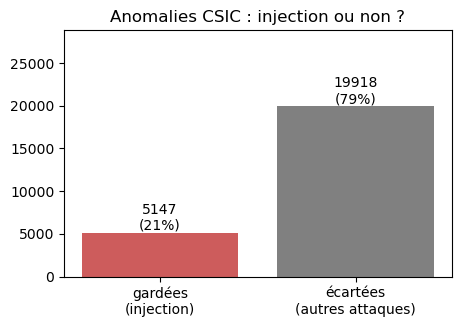

In [8]:
anom = raw[raw["classification"] == 1].copy()
anom["markers"] = anom["text"].map(injection_markers)       # ex. ['sql', 'special']

# nombre d'anomalies qui contiennent chaque famille (une requête peut en avoir plusieurs)
familles = {f: int(anom["markers"].map(lambda m: f in m).sum()) for f in ["sql", "xss", "special"]}
gardees = int((anom["markers"].map(len) > 0).sum())
ecartees = len(anom) - gardees
print("Familles de marqueurs :", familles)
print(f"Anomalies gardées (injection) : {gardees}")
print(f"Anomalies écartées            : {ecartees}")

plt.figure(figsize=(5, 3.2))
plt.bar(["gardées\n(injection)", "écartées\n(autres attaques)"], [gardees, ecartees], color=["indianred", "grey"])
for i, v in enumerate([gardees, ecartees]):
    plt.text(i, v, f"{v}\n({v/len(anom):.0%})", ha="center", va="bottom")
plt.ylim(0, len(anom) * 1.15)
plt.title("Anomalies CSIC : injection ou non ?")
plt.show()

**Interprétation.** Sur 25 065 anomalies, seulement **5 147 (~21 %)** ressemblent à une injection ; **19 918 (~79 %)**
sont d'autres types d'attaques. Les garder avec l'étiquette « injection » aurait appris au modèle à détecter des
choses sans rapport avec notre sujet. La famille *special* (5 066) domine ; *sql* (2 413) et *xss* (1 504) sont plus
précises mais plus rares : les trois familles sont utiles.

## 7. Contrôle manuel d'un échantillon (comme prévu dans la proposition)

 La proposition demande une **vérification manuelle** du filtre. On regarde (a) quelques anomalies
**écartées** (on veut qu'elles ne soient pas des injections) et (b) quelques anomalies **gardées**
(on veut qu'elles en soient).

In [9]:
anom["gardee"] = anom["markers"].map(len) > 0
print("=== ECARTEES (doivent NE PAS être des injections) ===")
for t in anom[~anom["gardee"]].sample(6, random_state=1)["text"]:
    print(" -", t[:170])
print("\n=== GARDEES (doivent être des injections) ===")
for t in anom[anom["gardee"]].sample(6, random_state=1)["text"]:
    print(" -", t[:170])

=== ECARTEES (doivent NE PAS être des injections) ===
 - get /tienda1/publico/anadir.jsp?id=any set-cookie: tamper=1041264011025374727&nombre=queso manchego&precio=85&cantidad=12&b1=añadir al carrito
 - get /tienda1/publico/autenticar.jsp?modo=entrar&login=?denise&pwd=plasmador&remember=on&b1=entrar
 - get /web-inf/web.xml
 - post /tienda1/publico/caracteristicas.jsp id=any? set-cookie: tamper=5765205567234876235
 - get /tienda1/miembros/editar.jsp?modo=registro&login=program&password=9bocelado&nombre=kasuhiro&apellidos=argandoña cobo&email=dufour_mannhardt@privatebanking.com.us&dni=
 - post /tienda1/publico/vaciar.jsp b2a=vaciar carrito

=== GARDEES (doivent être des injections) ===
 - get /tienda1/publico/autenticar.jsp?modo=entrar&login=lussier&pwd=1ch?u07l6a&remember=off&b1=paros" style="background:url(javascript:alert('paros'))
 - post /tienda1/publico/entrar.jsp errormsg=credenciales incorrectas<!--#exec cmd="ls /"-->
 - get /tienda1/miembros/editar.jsp?modo=registro&login=darn&p

**Interprétation.** Les écartées sont des scans de fichiers (`/web-inf/web.xml`), des paramètres renommés
(`b2a`, `provinciaa`), des valeurs corrompues par un `?` ou des attaques de **cookie/en-tête** (`set-cookie: tamper=...`) :
aucune n'est du SQLi ou du XSS, donc le filtre a bien fait son travail pour **notre** sujet. Les gardées contiennent de
vraies charges (`waitfor delay`, `drop table`, `<script>`, `javascript:alert`). Limites connues : l'injection d'en-tête
(`set-cookie`) et le séparateur shell `|` ne sont pas dans nos règles ; ces cas sont **hors périmètre** (SQLi/XSS) et
seront cités comme limite. L'échantillon de 100 lignes écartées est sauvegardé dans
`reports/csic_removed_anomalies_sample.csv` pour relecture croisée par l'équipe.

## 8. Requêtes normales qui contiennent un marqueur

Certaines requêtes **normales** contiennent une apostrophe ou une parenthèse (ex. une adresse). On
les **garde** : ce sont des « négatifs difficiles » qui apprennent au modèle qu'une apostrophe seule ne suffit pas.

In [10]:
normales = raw[raw["classification"] == 0].drop_duplicates("text")
avec_marqueur = normales[normales["text"].map(looks_like_injection)]
print(f"Normales uniques : {len(normales)} | avec un marqueur : {len(avec_marqueur)} ({len(avec_marqueur)/len(normales):.1%})")
for t in avec_marqueur["text"].head(3):
    print(" -", t[:200])

Normales uniques : 9644 | avec un marqueur : 104 (1.1%)
 - get /tienda1/miembros/editar.jsp?modo=registro&login=maurie&password=0strop5je0&nombre=vlentina&apellidos=fisas&email=marlaud_losee5@redesmilitantes.tf&dni=54430634f&direccion=viseu 81 8?c&ciudad=corb
 - post /tienda1/miembros/editar.jsp modo=registro&login=maurie&password=0strop5je0&nombre=vlentina&apellidos=fisas&email=marlaud_losee5@redesmilitantes.tf&dni=54430634f&direccion=viseu 81 8?c&ciudad=cor
 - get /tienda1/miembros/editar.jsp?modo=registro&login=threader&password=descolocado&nombre=mallki&apellidos=moreno undurraga&email=stevenin@ceramicasmiño.mn&dni=70153244r&direccion=c/ vapor, 148, 2?a&c


**Interprétation.** Seulement ~1 % des normales contiennent un marqueur : le modèle ne peut donc pas se contenter
de « un caractère spécial = attaque », il devra regarder le contexte. 

## 9. Lancer toute la chaîne : filtre, doublons, mélange et split 80/20

 La fonction `build()` de `src/preprocessing/build_csic.py` exécute tout dans le bon ordre et compte
les lignes à chaque étape : normaliser, filtrer, **dédupliquer**, retirer les conflits (même texte, deux étiquettes),
**mélanger** (graine 42) puis couper en **80 / 20 stratifié** (même proportion d'injections dans train et validation).
Elle écrit `train.csv`, `val.csv` (et `csic_clean.csv`) dans `data/processed/`.

In [11]:
from src.preprocessing.build_csic import build

resume = build()
tableau = pd.DataFrame(
    [
        ("Lignes brutes", resume["raw_rows"]),
        ("- anomalies non-injection écartées", resume["removed_non_injection_anomalies"]),
        ("= après filtre injection", resume["after_filter_rows"]),
        ("- doublons supprimés", resume["duplicates_removed"]),
        ("- conflits supprimés", resume["conflicting_rows_removed"]),
        ("= jeu final", resume["final_rows"]),
    ],
    columns=["étape", "lignes"],
)
tableau

,étape,lignes
0,Lignes brutes,61065
1,- anomalies non-injection écartées,19918
2,= après filtre injection,41147
3,- doublons supprimés,27802
4,- conflits supprimés,0
5,= jeu final,13345


**Interprétation.** On passe de **61 065 à 13 345 requêtes** : 9 644 normales et 3 701 injections. La
déduplication retire à elle seule 27 802 lignes. Aucun conflit ne reste car les requêtes ambiguës étaient des
anomalies sans marqueur, déjà écartées par le filtre. Le jeu est plus petit mais **propre et honnête** : le
nombre « officiel » d'injections à citer dans le rapport est **3 701**.

## 10. Vérifier le split train / validation

Trois contrôles : (1) proportions 80/20 ; (2) **même ratio d'injections** dans les deux parties
(stratification) ; (3) **aucune requête commune** entre train et validation (pas de fuite).

train:  10676 lignes | injections =  2961 (27.74%)
val  :   2669 lignes | injections =   740 (27.73%)
Textes communs train/val : 0


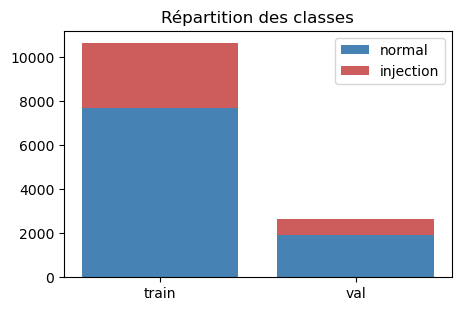

In [12]:
train = pd.read_csv(ROOT / "data" / "processed" / "train.csv")
val = pd.read_csv(ROOT / "data" / "processed" / "val.csv")

for nom, d in [("train", train), ("val", val)]:
    print(f"{nom:5s}: {len(d):6d} lignes | injections = {int(d['label'].sum()):5d} ({d['label'].mean():.2%})")

communes = set(train["text"]) & set(val["text"])
print("Textes communs train/val :", len(communes))

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(["train", "val"], [(train["label"] == 0).sum(), (val["label"] == 0).sum()], label="normal", color="steelblue")
ax.bar(["train", "val"], [(train["label"] == 1).sum(), (val["label"] == 1).sum()],
       bottom=[(train["label"] == 0).sum(), (val["label"] == 0).sum()], label="injection", color="indianred")
ax.set_title("Répartition des classes")
ax.legend()
plt.show()

**Interprétation.** 10 676 lignes en train et 2 669 en validation (80 / 20), avec **27,7 % d'injections dans les deux**
(stratification réussie) et **0 texte commun** : la validation mesure une vraie généralisation, pas une mémorisation.
Le déséquilibre (≈ 28 % d'injections) reste modéré : on le traitera avec `class_weight="balanced"` dans les modèles.

## 11. Conclusion

- Représentation commune : `méthode + chemin/params + corps`, décodée, minuscule, **PUT → post**.
- Filtre : **19 918** anomalies non-injection écartées ; **3 701** injections uniques conservées.
- Dédupliquer **avant** le split est essentiel (36 024 doublons « cachés » par les cookies).
- Fichiers prêts : `data/processed/train.csv` (10 676) et `val.csv` (2 669), **non versionnés** (voir `.gitignore`).

**Limites.** Le jeu final est réduit (13 345 lignes) ; le filtre est à base de règles
(quelques injections atypiques peuvent être perdues) ; le chemin `/tienda1/...` est propre à CSIC (risque de domain gap).

**Prochaine étape :** notebook 03, baseline régression logistique.